In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# CONFIG
# =========================
TIME_COL_CANDIDATES = ["times-tamp", "timestamp", "time", "ts"]
OP_COL = "op"
BYTES_COL = "bytes"
ENT_COL = "entropy"

# Kandidaten für B (KB)
B_CANDIDATES_KB = [4, 8, 16, 32, 64, 128, 256, 512]
MIN_BLOCKS = 50          # Mindestanzahl Blöcke, damit IQR brauchbar ist
IQR_TARGET = 0.30        # "stabil genug" (Bits/Byte) -> kann man später feinjustieren

# Fenstergrößen w (ms)
W_CANDIDATES_MS = list(range(250, 10001, 250))

# Coverage Ziel (Anteil aktiver Write-Fenster, die >= B_min erreichen)
COVERAGE_TARGET = 0.70
MIN_VALID_WINDOWS = 50   # mindestens so viele gültige Fenster pro Trace

Ransomware runs: 3
Benign runs:     3
Tau fixed:       7.5
DMAX:            10.0s
Benign-FP Mode:  within_dmax
CSV gespeichert: grid_eval_entropy_fixedtau_within10s.csv

BESTES (w,k) unter k*w<=10s (tau fix, Benign nur innerhalb 10s):
interval         100ms
k                    4
tau                7.5
TPR_trace          1.0
FPR_trace          0.0
J                  1.0
Delay_q90_sec      0.4


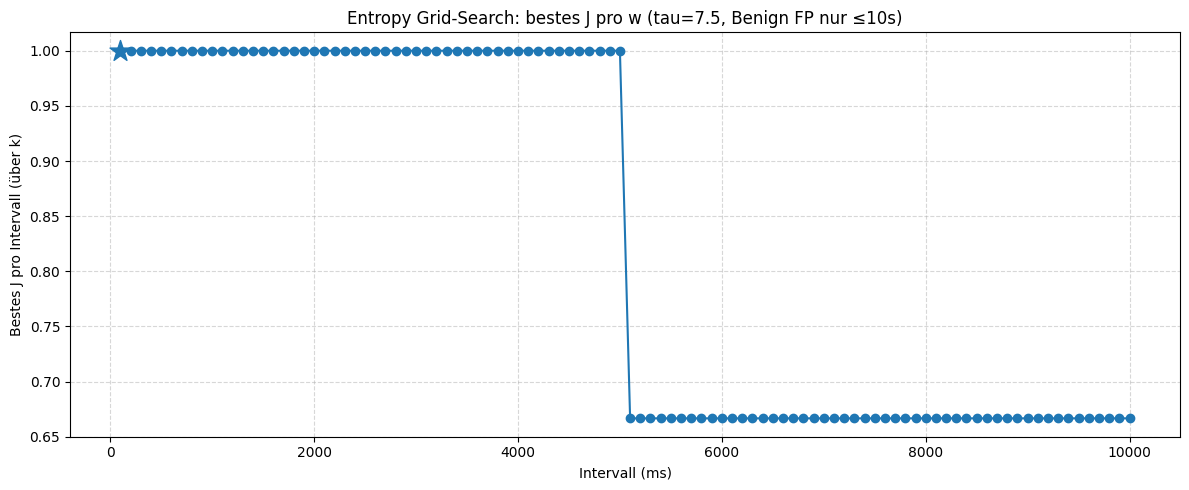

In [2]:
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ==============================================================================
# LOCATIONS (deine Pfade)
# ==============================================================================
BASE_RANSOM = Path("../logs/ransomware/monitor_logs_ransomware_with_entropy")
RANSOM_LOGS = sorted(BASE_RANSOM.glob("run*.csv"))

BASE_BENIGN = Path("../logs/benig/benign_entropy")
BENIGN_LOGS = sorted(BASE_BENIGN.glob("run*.csv"))


# ==============================================================================
# CONFIG
# ==============================================================================
TIME_COL = "timestamp"
OP_COL = "op"
ENT_COL = "entropy"

TAU_FIXED = 7.5          # fester Entropie-Schwellwert (verschlüsselt/komprimiert)
DMAX_SECONDS = 10.0      # max 10s bis Alarm
INTERVALS = [f"{ms}ms" for ms in range(100, 10_000 + 1, 100)]

# ✅ Benign zählt nur als FP, wenn Alarm innerhalb von 10s passiert
BENIGN_FP_MODE = "within_dmax"   # ("any" wäre: irgendwann im Run)

J_EPS = 1e-6
MAKE_PLOTS = True


# ==============================================================================
# HELPERS
# ==============================================================================
def load_and_prepare(path: Path, label: str) -> pd.DataFrame:
    df = pd.read_csv(path)

    for c in [TIME_COL, OP_COL, ENT_COL]:
        if c not in df.columns:
            raise ValueError(f"[{label}] CSV braucht Spalte '{c}'. Gefunden: {list(df.columns)}")

    df[TIME_COL] = pd.to_datetime(df[TIME_COL], utc=True, errors="raise")
    df = df.sort_values(TIME_COL).set_index(TIME_COL)

    # nur Writes verwenden (WRITE/pwrite/writev etc.)
    op = df[OP_COL].astype(str)
    is_write = op.str.contains("write", case=False, na=False)
    df = df.loc[is_write, [ENT_COL]].copy()

    df[ENT_COL] = pd.to_numeric(df[ENT_COL], errors="coerce")
    df = df.dropna(subset=[ENT_COL])

    df["label"] = label
    return df


def aggregate_windows_entropy(df_writes: pd.DataFrame, interval: str, tau: float) -> pd.DataFrame:
    """
    Nicht-overlappende Zeitfenster.
    mean_entropy = arithmetischer Mittelwert der Entropie der Writes im Fenster.
    active = Fenster hat >= 1 Write.
    suspect = active && mean_entropy >= tau.
    """
    if df_writes.empty:
        idx = pd.DatetimeIndex([], tz="UTC")
        return pd.DataFrame({"active": [], "mean_entropy": [], "suspect": [], "count_writes": []}, index=idx)

    mean_ent = df_writes.resample(interval, origin="start")[ENT_COL].mean()
    cnt = df_writes.resample(interval, origin="start")[ENT_COL].count()

    active = cnt > 0
    suspect = active & (mean_ent >= float(tau))

    return pd.DataFrame(
        {
            "active": active,
            "mean_entropy": mean_ent.astype(float),
            "suspect": suspect,
            "count_writes": cnt.astype(int),
        },
        index=mean_ent.index,
    )


def first_alarm_times_by_k(win: pd.DataFrame, interval_td: pd.Timedelta, kmax: int):
    """
    Ein Scan -> first_alarm_end[k] für k=1..kmax.

    Regel:
      - active=False (NO_DECISION): counter=0
      - active=True & suspect=True: counter++
      - active=True & suspect=False: counter=0
      - Alarm, sobald counter >= k (erstes Mal wird gespeichert)
    """
    idx = win.index
    first_alarm_end = np.array([None] * (kmax + 1), dtype=object)  # index 0 unbenutzt

    if len(idx) == 0:
        return None, first_alarm_end

    active = win["active"].to_numpy()
    suspect = win["suspect"].to_numpy()

    # erster aktiver Zeitpunkt (für Delay-Start)
    first_active_time = None
    for i in range(len(idx)):
        if active[i]:
            first_active_time = idx[i]
            break
    if first_active_time is None:
        return None, first_alarm_end

    counter = 0
    for i, t in enumerate(idx):
        if not active[i]:
            counter = 0
            continue

        if suspect[i]:
            counter += 1
            if counter > kmax:
                counter = kmax
            for k in range(1, counter + 1):
                if first_alarm_end[k] is None:
                    first_alarm_end[k] = t + interval_td  # Fenster-Endzeit
        else:
            counter = 0

    return first_active_time, first_alarm_end


def q90(values: list[float]) -> float:
    arr = np.array([v for v in values if v is not None and not np.isnan(v)], dtype=float)
    if arr.size == 0:
        return np.nan
    return float(np.quantile(arr, 0.90))


# ==============================================================================
# GRID SEARCH: alle (w,k) mit k*w <= DMAX
# ==============================================================================
def evaluate_all_pairs(
    ransom_dfs: list[pd.DataFrame],
    benign_dfs: list[pd.DataFrame],
    intervals: list[str],
    tau: float,
    dmax_seconds: float,
    benign_fp_mode: str,
) -> pd.DataFrame:
    rows = []

    for interval in intervals:
        interval_td = pd.to_timedelta(interval)
        w_seconds = interval_td.total_seconds()
        if w_seconds <= 0:
            continue

        kmax = max(int(np.floor(dmax_seconds / w_seconds)), 1)

        # Precompute per run (für dieses w)
        ransom_info = []
        for df in ransom_dfs:
            win = aggregate_windows_entropy(df, interval, tau)
            fa, alarm_end = first_alarm_times_by_k(win, interval_td, kmax)
            ransom_info.append((fa, alarm_end))

        benign_info = []
        for df in benign_dfs:
            win = aggregate_windows_entropy(df, interval, tau)
            fa, alarm_end = first_alarm_times_by_k(win, interval_td, kmax)
            benign_info.append((fa, alarm_end))

        for k in range(1, kmax + 1):
            # -------------------------
            # RANSOMWARE: Treffer, wenn Alarm innerhalb DMAX
            # -------------------------
            ransom_hits = []
            ransom_delays = []
            ransom_active_runs = 0

            for fa, alarm_end in ransom_info:
                if fa is None:
                    continue
                ransom_active_runs += 1

                if alarm_end[k] is None:
                    ransom_hits.append(0)
                    ransom_delays.append(np.nan)
                    continue

                delay = (alarm_end[k] - fa).total_seconds()
                if delay <= dmax_seconds:
                    ransom_hits.append(1)
                    ransom_delays.append(delay)
                else:
                    ransom_hits.append(0)
                    ransom_delays.append(np.nan)

            tpr_trace = float(np.mean(ransom_hits)) if ransom_active_runs > 0 else np.nan
            delay_q90 = q90(ransom_delays)

            # -------------------------
            # BENIGN: False Positive
            # -------------------------
            benign_fp = []
            benign_active_runs = 0

            for fa, alarm_end in benign_info:
                if fa is None:
                    continue
                benign_active_runs += 1

                if alarm_end[k] is None:
                    benign_fp.append(0)
                    continue

                if benign_fp_mode == "within_dmax":
                    delay = (alarm_end[k] - fa).total_seconds()
                    benign_fp.append(1 if delay <= dmax_seconds else 0)
                elif benign_fp_mode == "any":
                    benign_fp.append(1)
                else:
                    raise ValueError("benign_fp_mode must be 'any' or 'within_dmax'.")

            fpr_trace = float(np.mean(benign_fp)) if benign_active_runs > 0 else np.nan
            J = (tpr_trace - fpr_trace) if (not np.isnan(tpr_trace) and not np.isnan(fpr_trace)) else np.nan

            rows.append(
                {
                    "interval": interval,
                    "interval_ms": int(w_seconds * 1000),
                    "tau": float(tau),
                    "k": k,
                    "kmax_for_interval": kmax,
                    "TPR_trace": tpr_trace,
                    "FPR_trace": fpr_trace,
                    "J": J,
                    "Delay_q90_sec": delay_q90,
                    "active_ransom_runs": ransom_active_runs,
                    "active_benign_runs": benign_active_runs,
                    "benign_fp_mode": benign_fp_mode,
                }
            )

    return pd.DataFrame(rows)


def pick_best_pair(eval_df: pd.DataFrame) -> pd.Series | None:
    tmp = eval_df.dropna(subset=["J"]).copy()
    if tmp.empty:
        return None

    j_max = float(tmp["J"].max())
    cand = tmp[tmp["J"] >= (j_max - J_EPS)].copy()

    # Tie-breaker: kleiner Delay, dann kleiner w, dann kleiner k
    cand["Delay_q90_fill"] = cand["Delay_q90_sec"].fillna(np.inf)
    cand = cand.sort_values(["Delay_q90_fill", "interval_ms", "k"], ascending=[True, True, True])
    return cand.iloc[0]


def best_per_interval(eval_df: pd.DataFrame) -> pd.DataFrame:
    tmp = eval_df.dropna(subset=["J"]).copy()
    if tmp.empty:
        return tmp

    tmp["Delay_q90_fill"] = tmp["Delay_q90_sec"].fillna(np.inf)
    tmp = tmp.sort_values(["interval_ms", "J", "Delay_q90_fill", "k"], ascending=[True, False, True, True])
    out = tmp.groupby("interval_ms", as_index=False).first()
    return out.drop(columns=["Delay_q90_fill"], errors="ignore")


# ==============================================================================
# MAIN
# ==============================================================================
def main():
    if not RANSOM_LOGS:
        raise RuntimeError(f"Keine Ransomware-Logs gefunden in: {BASE_RANSOM}")
    if not BENIGN_LOGS:
        raise RuntimeError(f"Keine Benign-Logs gefunden in: {BASE_BENIGN}")

    print(f"Ransomware runs: {len(RANSOM_LOGS)}")
    print(f"Benign runs:     {len(BENIGN_LOGS)}")
    print(f"Tau fixed:       {TAU_FIXED}")
    print(f"DMAX:            {DMAX_SECONDS}s")
    print(f"Benign-FP Mode:  {BENIGN_FP_MODE}")

    ransom_dfs = [load_and_prepare(p, f"R_{p.stem}") for p in RANSOM_LOGS]
    benign_dfs = [load_and_prepare(p, f"B_{p.stem}") for p in BENIGN_LOGS]

    eval_df = evaluate_all_pairs(
        ransom_dfs=ransom_dfs,
        benign_dfs=benign_dfs,
        intervals=INTERVALS,
        tau=TAU_FIXED,
        dmax_seconds=DMAX_SECONDS,
        benign_fp_mode=BENIGN_FP_MODE,
    )

    out_csv = "grid_eval_entropy_fixedtau_within10s.csv"
    eval_df.to_csv(out_csv, index=False)
    print(f"CSV gespeichert: {out_csv}")

    best = pick_best_pair(eval_df)
    if best is None:
        print("Kein bestes (w,k) gefunden (zu viele NaNs / keine aktiven Fenster?).")
        return

    print("\nBESTES (w,k) unter k*w<=10s (tau fix, Benign nur innerhalb 10s):")
    print(best[["interval", "k", "tau", "TPR_trace", "FPR_trace", "J", "Delay_q90_sec"]].to_string())

    if not MAKE_PLOTS:
        return

    best_w_df = best_per_interval(eval_df)
    best_w = int(best["interval_ms"])
    best_J = float(best["J"])

    plt.figure(figsize=(12, 5))
    plt.plot(best_w_df["interval_ms"], best_w_df["J"], marker="o")
    plt.scatter([best_w], [best_J], marker="*", s=250, zorder=5)
    plt.xlabel("Intervall (ms)")
    plt.ylabel("Bestes J pro Intervall (über k)")
    plt.title("Entropy Grid-Search: bestes J pro w (tau=7.5, Benign FP nur ≤10s)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()


BEST (rw_no_entropy):
interval                 2500ms
k                             2
R_Qp_trigger_rate      0.897877
B_Q1-p_trigger_rate         0.0
J                      0.897877


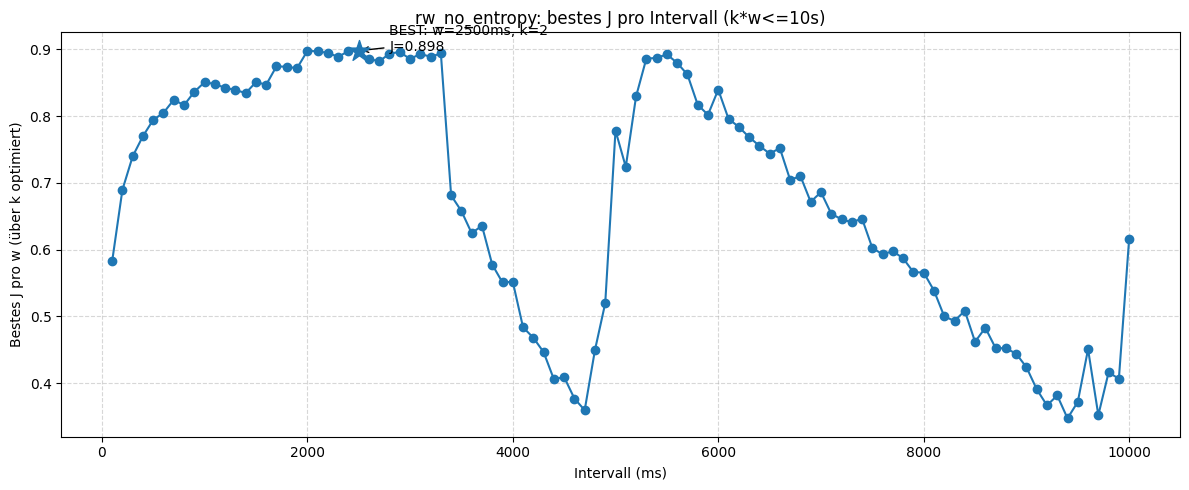


BEST (entropy):
interval                 2500ms
k                             3
R_Qp_trigger_rate      0.940636
B_Q1-p_trigger_rate     0.00315
J                      0.937486


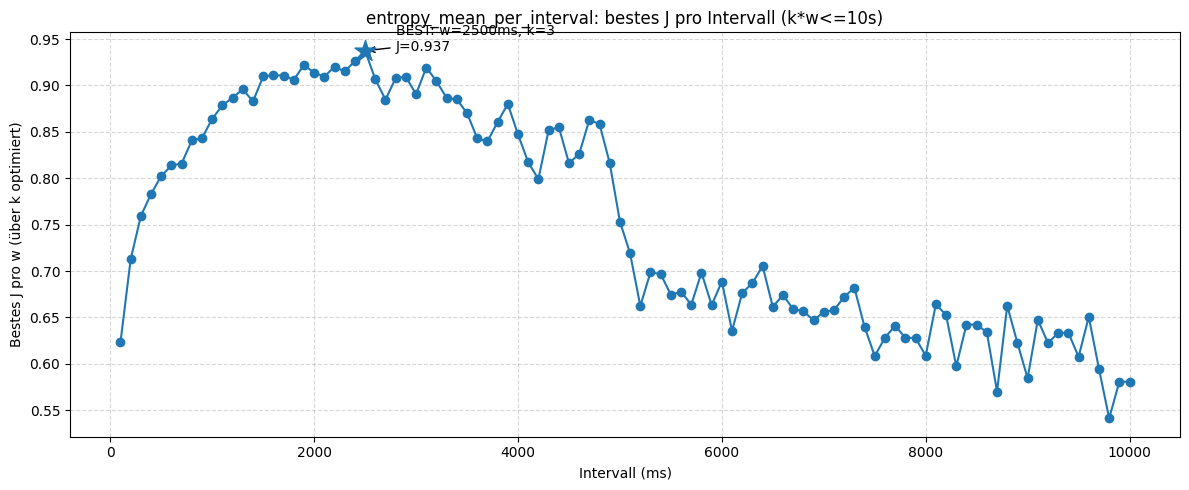


CSV gespeichert: grid_eval_combined_rw_and_entropy.csv


In [ ]:
from __future__ import annotations

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ==============================================================================
# PATHS (wie du sie angegeben hast)
# ==============================================================================
BASE_RANSOM_NO_ENTROPY = Path("../logs/ransomware/monitor_logs_ransomware_no_entropy")
RANSOM_LOGS_NO_ENTROPY = sorted(BASE_RANSOM_NO_ENTROPY.glob("run*.csv"))

BASE_BENIGN_NO_ENTROPY = Path("../logs/benig/benig_no_entropy")
BENIGN_LOGS_NO_ENTROPY = sorted(BASE_BENIGN_NO_ENTROPY.glob("run*.csv"))

BASE_RANSOM_WITH_ENTROPY = Path("../logs/ransomware/monitor_logs_ransomware_with_entropy")
RANSOM_LOGS_WITH_ENTROPY = sorted(BASE_RANSOM_WITH_ENTROPY.glob("run*.csv"))

BASE_BENIGN_WITH_ENTROPY = Path("../logs/benig/benign_entropy")
BENIGN_LOGS_WITH_ENTROPY = sorted(BASE_BENIGN_WITH_ENTROPY.glob("run*.csv"))


# ==============================================================================
# CONFIG
# ==============================================================================
TIME_COL = "timestamp"
OP_COL = "op"
ENTROPY_COL = "entropy"

THETA_PAPER = 0.337480   # RW-threshold
ENTROPY_THR = 7.5        # Entropy-threshold (>=)
DMAX_SECONDS = 10.0
INTERVALS = [f"{ms}ms" for ms in range(100, 10_000 + 1, 100)]

P_QUANTILE = 0.10
J_EPS = 1e-9
MAKE_PLOTS = True


# ==============================================================================
# LOAD
# ==============================================================================
def load_and_prepare(path: Path, label: str) -> pd.DataFrame:
    df = pd.read_csv(path)

    if TIME_COL not in df.columns:
        raise ValueError(f"[{label}] CSV braucht Spalte '{TIME_COL}'. Gefunden: {list(df.columns)}")

    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="raise")
    df = df.sort_values(TIME_COL).set_index(TIME_COL)
    df["label"] = label

    # Reads/Writes vorbereiten falls OP_COL existiert
    if OP_COL in df.columns:
        op = df[OP_COL].astype(str)
        df["reads"] = op.str.contains("read", case=False, na=False).astype(int)
        df["writes"] = op.str.contains("write", case=False, na=False).astype(int)

    # Entropy als numeric (falls vorhanden)
    if ENTROPY_COL in df.columns:
        df[ENTROPY_COL] = pd.to_numeric(df[ENTROPY_COL], errors="coerce")

    return df


# ==============================================================================
# WINDOW FEATURE EXTRACTION (immer gleich)
# ==============================================================================
def build_window_features(df: pd.DataFrame, interval: str) -> pd.DataFrame:
    """
    Baut pro Fenster Features, unabhängig davon, welche Suspect-Regel du später nutzt.

    Features (wenn verfügbar):
      - reads_sum, writes_sum
      - entropy_mean (Durchschnitt pro Intervall) + entropy_count
    active-Definition (wichtig, wie du wolltest):
      - wenn reads/writes existieren: active := (reads_sum + writes_sum > 0)
      - sonst: active := (entropy_count > 0)
    """
    # Resample reads/writes
    if "reads" in df.columns and "writes" in df.columns:
        rw = df.resample(interval, origin="start")[["reads", "writes"]].sum()
        rw = rw.rename(columns={"reads": "reads_sum", "writes": "writes_sum"})
    else:
        # leeres DF mit Index der Resample-Bins erzeugen
        rw = df.resample(interval, origin="start").size().to_frame("dummy")
        rw = rw.drop(columns=["dummy"])

    # Resample entropy mean
    if ENTROPY_COL in df.columns:
        ent = df.resample(interval, origin="start")[ENTROPY_COL].agg(["mean", "count"])
        ent = ent.rename(columns={"mean": "entropy_mean", "count": "entropy_count"})
    else:
        ent = df.resample(interval, origin="start").size().to_frame("entropy_count")
        ent["entropy_mean"] = np.nan

    feats = rw.join(ent, how="outer")

    # Active-Regel: primär I/O Aktivität (r+w>0), sonst Entropy Count
    if "reads_sum" in feats.columns and "writes_sum" in feats.columns:
        denom = feats["reads_sum"].astype(float) + feats["writes_sum"].astype(float)
        active = denom > 0
    else:
        active = feats["entropy_count"].astype(float) > 0

    feats["active"] = active
    return feats


# ==============================================================================
# SUSPECT CALLBACKS (austauschbar!)
# ==============================================================================
def suspect_rw_theta(features: pd.DataFrame, theta: float) -> pd.Series:
    """
    Suspect-Regel RW:
      d = |r-w|/(r+w) für aktive Fenster
      suspect := (d <= theta)
    """
    if "reads_sum" not in features.columns or "writes_sum" not in features.columns:
        raise ValueError("RW suspect_fn: reads_sum/writes_sum fehlen in Features.")

    r = features["reads_sum"].astype(float)
    w = features["writes_sum"].astype(float)
    denom = r + w

    d = pd.Series(np.nan, index=features.index, dtype=float)
    active = features["active"].to_numpy()
    d.loc[active] = (r.loc[active] - w.loc[active]).abs() / denom.loc[active]

    features["metric"] = d  # optional fürs Debug/Plots
    return (d <= theta) & features["active"]


def suspect_entropy_threshold(features: pd.DataFrame, thr: float) -> pd.Series:
    """
    Suspect-Regel Entropy:
      entropy_mean wird pro Intervall berechnet
      suspect := (entropy_mean >= thr) für aktive Fenster
    """
    if "entropy_mean" not in features.columns:
        raise ValueError("Entropy suspect_fn: entropy_mean fehlt in Features.")

    metric = features["entropy_mean"].astype(float)
    features["metric"] = metric  # optional
    return (metric >= thr) & features["active"]


# ==============================================================================
# SEGMENT-TRIGGER-RATE
# ==============================================================================
def trigger_rate_from_segments(active: np.ndarray, suspect: np.ndarray, k: int) -> float:
    """
    trigger_rate = (#k-consecutive suspect blocks) / (#possible starts)
    NO_DECISION => active=False => Segment-Grenze.
    possible pro Segment = L-k+1
    """
    triggers_total = 0
    possible_total = 0

    n = len(active)
    i = 0
    while i < n:
        if not active[i]:
            i += 1
            continue

        j = i
        while j < n and active[j]:
            j += 1

        seg = suspect[i:j].astype(np.int32)
        L = seg.size

        if L >= k:
            possible_total += (L - k + 1)
            sums = np.convolve(seg, np.ones(k, dtype=np.int32), mode="valid")
            triggers_total += int(np.sum(sums == k))

        i = j

    if possible_total == 0:
        return np.nan
    return triggers_total / possible_total


def nan_quantile(values: list[float], q: float) -> float:
    arr = np.array(values, dtype=float)
    arr = arr[~np.isnan(arr)]
    if arr.size == 0:
        return np.nan
    return float(np.quantile(arr, q))


# ==============================================================================
# GRID SEARCH (Algorithmus ist komplett entkoppelt, nur suspect_fn ist variabel)
# ==============================================================================
def evaluate_grid_quantile_triggerrate(
    experiment_name: str,
    ransom_dfs: list[pd.DataFrame],
    benign_dfs: list[pd.DataFrame],
    suspect_fn,  # callback: (features_df) -> suspect_series
) -> pd.DataFrame:
    rows = []

    for interval in INTERVALS:
        td = pd.to_timedelta(interval)
        w_s = td.total_seconds()
        if w_s <= 0:
            continue

        kmax = int(np.floor(DMAX_SECONDS / w_s))
        if kmax < 1:
            kmax = 1

        # Precompute windowed features + suspect per run
        r_windows = []
        for df in ransom_dfs:
            feats = build_window_features(df, interval)
            suspect = suspect_fn(feats)              # <-- NUR HIER hängt’s von RW vs Entropy ab
            r_windows.append((feats["active"].to_numpy(), suspect.to_numpy()))

        b_windows = []
        for df in benign_dfs:
            feats = build_window_features(df, interval)
            suspect = suspect_fn(feats)
            b_windows.append((feats["active"].to_numpy(), suspect.to_numpy()))

        for k in range(1, kmax + 1):
            r_rates = [trigger_rate_from_segments(a, s, k) for (a, s) in r_windows]
            b_rates = [trigger_rate_from_segments(a, s, k) for (a, s) in b_windows]

            R = nan_quantile(r_rates, P_QUANTILE)
            B = nan_quantile(b_rates, 1.0 - P_QUANTILE)
            J = (R - B) if (not np.isnan(R) and not np.isnan(B)) else np.nan

            rows.append({
                "experiment": experiment_name,
                "interval": interval,
                "interval_ms": int(w_s * 1000),
                "k": k,
                "kmax_for_interval": kmax,
                "R_Qp_trigger_rate": R,
                "B_Q1-p_trigger_rate": B,
                "J": J,
                "p_quantile": P_QUANTILE,
            })

    return pd.DataFrame(rows)


def pick_best(eval_df: pd.DataFrame) -> pd.Series | None:
    tmp = eval_df.dropna(subset=["J"]).copy()
    if tmp.empty:
        return None
    j_max = float(tmp["J"].max())
    cand = tmp[tmp["J"] >= (j_max - J_EPS)].copy()
    cand = cand.sort_values(["interval_ms", "k"], ascending=[True, True])
    return cand.iloc[0]


def best_per_interval(eval_df: pd.DataFrame) -> pd.DataFrame:
    tmp = eval_df.dropna(subset=["J"]).copy()
    if tmp.empty:
        return tmp
    tmp = tmp.sort_values(["interval_ms", "J", "k"], ascending=[True, False, True])
    return tmp.groupby("interval_ms", as_index=False).first()


def plot_results(eval_df: pd.DataFrame, best: pd.Series):
    exp = str(best["experiment"])
    best_w = int(best["interval_ms"])
    best_k = int(best["k"])
    best_J = float(best["J"])

    best_w_df = best_per_interval(eval_df)

    plt.figure(figsize=(12, 5))
    plt.plot(best_w_df["interval_ms"], best_w_df["J"], marker="o")
    plt.scatter([best_w], [best_J], marker="*", s=250, zorder=5)
    plt.annotate(
        f"BEST: w={best_w}ms, k={best_k}\nJ={best_J:.3f}",
        xy=(best_w, best_J),
        xytext=(best_w + 300, best_J),
        arrowprops=dict(arrowstyle="->"),
    )
    plt.xlabel("Intervall (ms)")
    plt.ylabel("Bestes J pro w (über k optimiert)")
    plt.title(f"{exp}: bestes J pro Intervall (k*w<=10s)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# ==============================================================================
# MAIN: führt RW(no entropy) und Entropy(with entropy) mit gleicher Pipeline aus
# ==============================================================================
def main():
    # ---------- RW / NO_ENTROPY ----------
    if not RANSOM_LOGS_NO_ENTROPY or not BENIGN_LOGS_NO_ENTROPY:
        raise RuntimeError("No-entropy Logs nicht gefunden (prüfe Pfade).")

    ransom_rw = [load_and_prepare(p, f"R_RW_{p.stem}") for p in RANSOM_LOGS_NO_ENTROPY]
    benign_rw = [load_and_prepare(p, f"B_RW_{p.stem}") for p in BENIGN_LOGS_NO_ENTROPY]

    def rw_callback(features: pd.DataFrame) -> pd.Series:
        return suspect_rw_theta(features, theta=THETA_PAPER)

    eval_rw = evaluate_grid_quantile_triggerrate(
        experiment_name="rw_no_entropy",
        ransom_dfs=ransom_rw,
        benign_dfs=benign_rw,
        suspect_fn=rw_callback,
    )
    eval_rw.to_csv("grid_eval_rw_no_entropy_quantile_trigger_rate.csv", index=False)
    best_rw = pick_best(eval_rw)
    print("\nBEST (rw_no_entropy):")
    print(best_rw[["interval","k","R_Qp_trigger_rate","B_Q1-p_trigger_rate","J"]].to_string())

    if MAKE_PLOTS:
        plot_results(eval_rw, best_rw)

    # ---------- ENTROPY / WITH_ENTROPY ----------
    if not RANSOM_LOGS_WITH_ENTROPY or not BENIGN_LOGS_WITH_ENTROPY:
        raise RuntimeError("Entropy Logs nicht gefunden (prüfe Pfade).")

    ransom_ent = [load_and_prepare(p, f"R_ENT_{p.stem}") for p in RANSOM_LOGS_WITH_ENTROPY]
    benign_ent = [load_and_prepare(p, f"B_ENT_{p.stem}") for p in BENIGN_LOGS_WITH_ENTROPY]

    def entropy_callback(features: pd.DataFrame) -> pd.Series:
        # durchschnittliche Entropy pro Intervall wurde bereits in build_window_features() berechnet
        return suspect_entropy_threshold(features, thr=ENTROPY_THR)

    eval_ent = evaluate_grid_quantile_triggerrate(
        experiment_name="entropy_mean_per_interval",
        ransom_dfs=ransom_ent,
        benign_dfs=benign_ent,
        suspect_fn=entropy_callback,
    )
    eval_ent.to_csv("grid_eval_entropy_mean_quantile_trigger_rate.csv", index=False)
    best_ent = pick_best(eval_ent)
    print("\nBEST (entropy):")
    print(best_ent[["interval","k","R_Qp_trigger_rate","B_Q1-p_trigger_rate","J"]].to_string())

    if MAKE_PLOTS:
        plot_results(eval_ent, best_ent)

    # Combined (optional)
    combined = pd.concat([eval_rw, eval_ent], ignore_index=True)
    combined.to_csv("grid_eval_combined_rw_and_entropy.csv", index=False)
    print("\nCSV gespeichert: grid_eval_combined_rw_and_entropy.csv")


if __name__ == "__main__":
    main()


BEST (rw_symmetry):
interval                 2500ms
k                             2
R_Qp_trigger_rate      0.897877
B_Q1-p_trigger_rate         0.0
J                      0.897877


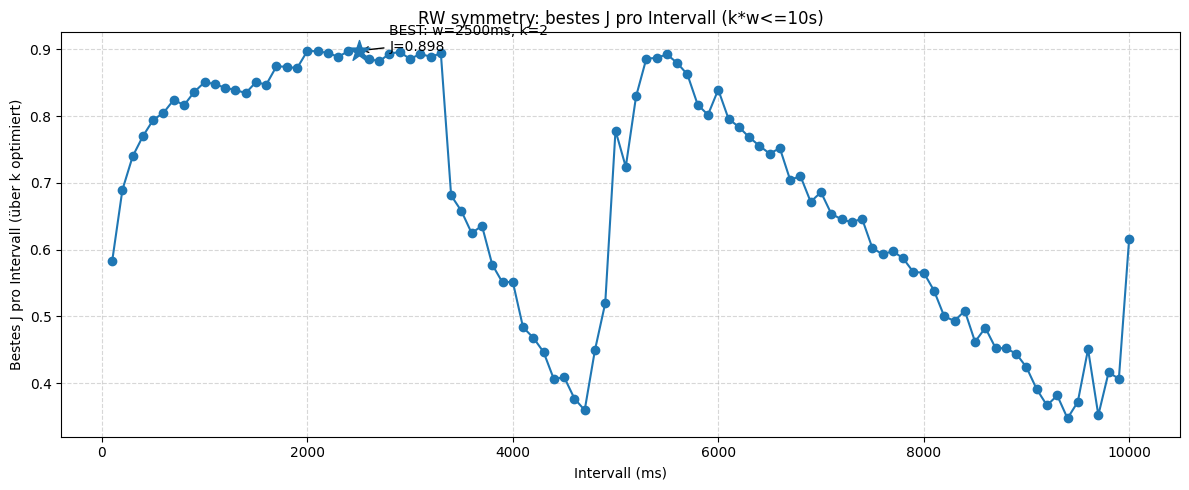


BEST (entropy_mean):
interval                 2500ms
k                             3
R_Qp_trigger_rate      0.940636
B_Q1-p_trigger_rate     0.00315
J                      0.937486


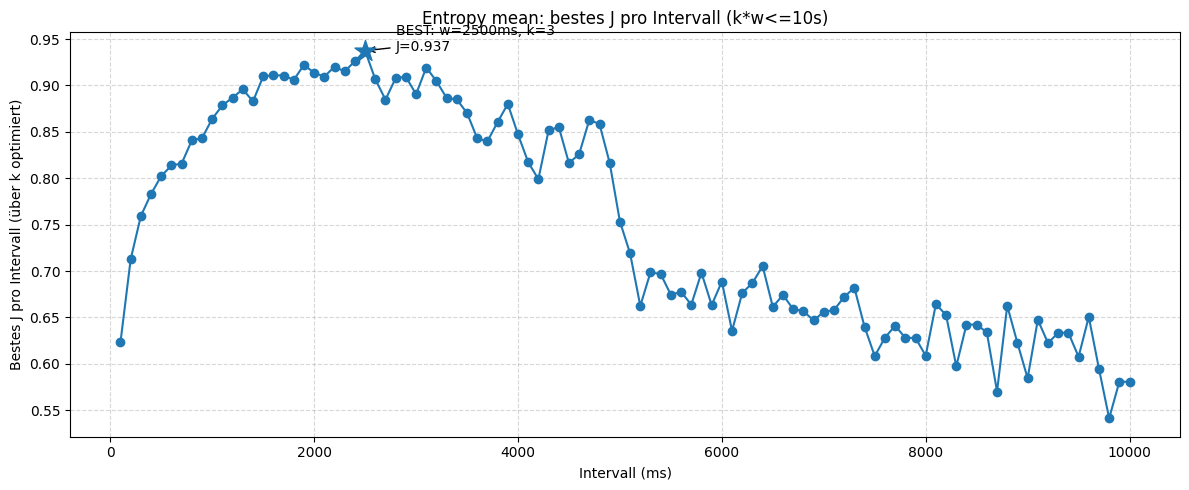


CSV gespeichert: grid_eval_combined.csv


In [5]:
from __future__ import annotations

from pathlib import Path
from typing import Callable

import numpy as np
import pandas as pd

# Optional (nur wenn MAKE_PLOTS=True)
import matplotlib.pyplot as plt


# ==============================================================================
# PATHS
# ==============================================================================
BASE_RANSOM_NO_ENTROPY = Path("../logs/ransomware/monitor_logs_ransomware_no_entropy")
RANSOM_LOGS_NO_ENTROPY = sorted(BASE_RANSOM_NO_ENTROPY.glob("run*.csv"))

BASE_BENIGN_NO_ENTROPY = Path("../logs/benig/benig_no_entropy")
BENIGN_LOGS_NO_ENTROPY = sorted(BASE_BENIGN_NO_ENTROPY.glob("run*.csv"))

BASE_RANSOM_WITH_ENTROPY = Path("../logs/ransomware/monitor_logs_ransomware_with_entropy")
RANSOM_LOGS_WITH_ENTROPY = sorted(BASE_RANSOM_WITH_ENTROPY.glob("run*.csv"))

BASE_BENIGN_WITH_ENTROPY = Path("../logs/benig/benign_entropy")
BENIGN_LOGS_WITH_ENTROPY = sorted(BASE_BENIGN_WITH_ENTROPY.glob("run*.csv"))


# ==============================================================================
# CONFIG
# ==============================================================================
TIME_COL = "timestamp"
OP_COL = "op"
BYTES_COL = "bytes"
ENTROPY_COL = "entropy"

RW_SYMMETRY_THRESHOLD = 0.337480
ENTROPY_THRESHOLD = 7.5

DMAX_SECONDS = 10.0
INTERVALS = [f"{ms}ms" for ms in range(100, 10_000 + 1, 100)]

P_QUANTILE_WORST_RANSOMWARE = 0.10
J_EPS = 1e-9
MAKE_PLOTS = True


# ==============================================================================
# TYPES
# ==============================================================================
SuspectFn = Callable[[pd.DataFrame], pd.Series]
# callback(features_df) -> pd.Series[bool] (Index = window timestamps)


# ==============================================================================
# LOAD
# ==============================================================================
def load_run_csv(path: Path, label: str) -> pd.DataFrame:
    df = pd.read_csv(path)

    if TIME_COL not in df.columns:
        raise ValueError(f"[{label}] missing '{TIME_COL}'. Columns: {list(df.columns)}")

    # ISO timestamps with 'Z' + nanoseconds are fine with pandas; use utc for safety.
    df[TIME_COL] = pd.to_datetime(df[TIME_COL], utc=True, errors="raise")
    df = df.sort_values(TIME_COL).set_index(TIME_COL)
    df["label"] = label

    if OP_COL in df.columns:
        df[OP_COL] = df[OP_COL].astype(str)

    if BYTES_COL in df.columns:
        df[BYTES_COL] = pd.to_numeric(df[BYTES_COL], errors="coerce")

    if ENTROPY_COL in df.columns:
        df[ENTROPY_COL] = pd.to_numeric(df[ENTROPY_COL], errors="coerce")

    return df


# ==============================================================================
# WINDOW FEATURES
# ==============================================================================
def build_window_features(df: pd.DataFrame, interval: str) -> pd.DataFrame:
    """
    Pro Fenster (interval) werden Features aggregiert.
    Active-Regel (wie im Konzept):
      - wenn reads/writes vorhanden: active := (reads_sum + writes_sum > 0)
      - sonst: active := (entropy_count > 0) falls entropy vorhanden
      - sonst: active := (event_count > 0)
    """
    # Grundgerüst: Fensterindex erzeugen über count
    feats = df.resample(interval, origin="start").size().to_frame("event_count")

    # Reads/Writes counts (falls op da ist)
    if OP_COL in df.columns:
        op = df[OP_COL].astype(str)
        reads = op.str.contains("read", case=False, na=False).astype(int)
        writes = op.str.contains("write", case=False, na=False).astype(int)

        rw = pd.DataFrame({"reads": reads, "writes": writes}, index=df.index).resample(
            interval, origin="start"
        ).sum()
        feats["reads_sum"] = rw["reads"].astype(int)
        feats["writes_sum"] = rw["writes"].astype(int)
    else:
        feats["reads_sum"] = np.nan
        feats["writes_sum"] = np.nan

    # Bytes sum (optional)
    if BYTES_COL in df.columns:
        feats["bytes_sum"] = df[BYTES_COL].resample(interval, origin="start").sum(min_count=1)
    else:
        feats["bytes_sum"] = np.nan

    # Entropy aggregates (optional)
    if ENTROPY_COL in df.columns:
        ent = df[ENTROPY_COL].resample(interval, origin="start").agg(["mean", "count"])
        feats["entropy_mean"] = ent["mean"]
        feats["entropy_count"] = ent["count"].astype(int)
    else:
        feats["entropy_mean"] = np.nan
        feats["entropy_count"] = 0

    # Active-Regel
    if "reads_sum" in feats.columns and "writes_sum" in feats.columns and feats["reads_sum"].notna().any():
        denom = feats["reads_sum"].astype(float) + feats["writes_sum"].astype(float)
        feats["active"] = denom > 0
    elif ENTROPY_COL in df.columns:
        feats["active"] = feats["entropy_count"].astype(int) > 0
    else:
        feats["active"] = feats["event_count"].astype(int) > 0

    return feats


# ==============================================================================
# CALLBACKS (SUSPECT)
# ==============================================================================
def make_entropy_callback(thr: float = ENTROPY_THRESHOLD) -> SuspectFn:
    """
    suspect := (entropy_mean >= thr) AND active
    """
    def _fn(features: pd.DataFrame) -> pd.Series:
        if "entropy_mean" not in features.columns:
            raise ValueError("Entropy callback: 'entropy_mean' missing in features.")
        metric = pd.to_numeric(features["entropy_mean"], errors="coerce")
        return (metric >= float(thr)) & features["active"].astype(bool)

    return _fn


def make_rw_symmetry_callback(theta: float = RW_SYMMETRY_THRESHOLD) -> SuspectFn:
    """
    d_i = |r_i - w_i| / (r_i + w_i) (nur in active Fenstern)
    suspect := (d_i <= theta) AND active
    """
    def _fn(features: pd.DataFrame) -> pd.Series:
        if "reads_sum" not in features.columns or "writes_sum" not in features.columns:
            raise ValueError("RW callback: 'reads_sum'/'writes_sum' missing in features.")

        r = pd.to_numeric(features["reads_sum"], errors="coerce").fillna(0.0)
        w = pd.to_numeric(features["writes_sum"], errors="coerce").fillna(0.0)
        active = features["active"].astype(bool)

        denom = r + w
        d = pd.Series(np.nan, index=features.index, dtype=float)

        mask = active & (denom > 0)
        d.loc[mask] = (r.loc[mask] - w.loc[mask]).abs() / denom.loc[mask]

        return (d <= float(theta)) & active

    return _fn


# ==============================================================================
# TRIGGER RATE (k consecutive suspect inside active segments)
# ==============================================================================
def trigger_rate_from_segments(active: np.ndarray, suspect: np.ndarray, k: int) -> float:
    triggers_total = 0
    possible_total = 0

    n = len(active)
    i = 0
    while i < n:
        if not active[i]:
            i += 1
            continue

        j = i
        while j < n and active[j]:
            j += 1

        seg = suspect[i:j].astype(np.int32)
        L = seg.size

        if L >= k:
            possible_total += (L - k + 1)
            sums = np.convolve(seg, np.ones(k, dtype=np.int32), mode="valid")
            triggers_total += int(np.sum(sums == k))

        i = j

    if possible_total == 0:
        return np.nan
    return triggers_total / possible_total


def nan_quantile(values: list[float], q: float) -> float:
    arr = np.asarray(values, dtype=float)
    arr = arr[~np.isnan(arr)]
    if arr.size == 0:
        return np.nan
    return float(np.quantile(arr, q))


# ==============================================================================
# GRID EVALUATION
# ==============================================================================
def evaluate_grid_quantile_triggerrate(
    experiment_name: str,
    ransom_dfs: list[pd.DataFrame],
    benign_dfs: list[pd.DataFrame],
    suspect_fn: SuspectFn,
) -> pd.DataFrame:
    rows: list[dict] = []

    for interval in INTERVALS:
        w_s = pd.to_timedelta(interval).total_seconds()
        if w_s <= 0:
            continue

        kmax = max(1, int(np.floor(DMAX_SECONDS / w_s)))

        # Precompute active/suspect arrays per run for this interval
        r_ws: list[tuple[np.ndarray, np.ndarray]] = []
        for df in ransom_dfs:
            feats = build_window_features(df, interval)
            s = suspect_fn(feats).astype(bool).to_numpy()
            a = feats["active"].astype(bool).to_numpy()
            s = s & a
            r_ws.append((a, s))

        b_ws: list[tuple[np.ndarray, np.ndarray]] = []
        for df in benign_dfs:
            feats = build_window_features(df, interval)
            s = suspect_fn(feats).astype(bool).to_numpy()
            a = feats["active"].astype(bool).to_numpy()
            s = s & a
            b_ws.append((a, s))

        for k in range(1, kmax + 1):
            r_rates = [trigger_rate_from_segments(a, s, k) for (a, s) in r_ws]
            b_rates = [trigger_rate_from_segments(a, s, k) for (a, s) in b_ws]

            p = P_QUANTILE_WORST_RANSOMWARE
            R = nan_quantile(r_rates, p)
            B = nan_quantile(b_rates, 1.0 - p)
            J = (R - B) if (not np.isnan(R) and not np.isnan(B)) else np.nan

            rows.append({
                "experiment": experiment_name,
                "interval": interval,
                "interval_ms": int(w_s * 1000),
                "k": k,
                "kmax_for_interval": kmax,
                "R_Qp_trigger_rate": R,
                "B_Q1-p_trigger_rate": B,
                "J": J,
                "p_quantile": p,
            })

    return pd.DataFrame(rows)


def pick_best(eval_df: pd.DataFrame) -> pd.Series | None:
    tmp = eval_df.dropna(subset=["J"]).copy()
    if tmp.empty:
        return None
    j_max = float(tmp["J"].max())
    cand = tmp[tmp["J"] >= (j_max - J_EPS)].copy()
    cand = cand.sort_values(["interval_ms", "k"], ascending=[True, True])
    return cand.iloc[0]


def best_per_interval(eval_df: pd.DataFrame) -> pd.DataFrame:
    tmp = eval_df.dropna(subset=["J"]).copy()
    if tmp.empty:
        return tmp
    tmp = tmp.sort_values(["interval_ms", "J", "k"], ascending=[True, False, True])
    return tmp.groupby("interval_ms", as_index=False).first()


def plot_results(eval_df: pd.DataFrame, best: pd.Series, title: str):
    best_w = int(best["interval_ms"])
    best_k = int(best["k"])
    best_J = float(best["J"])

    best_w_df = best_per_interval(eval_df)

    plt.figure(figsize=(12, 5))
    plt.plot(best_w_df["interval_ms"], best_w_df["J"], marker="o")
    plt.scatter([best_w], [best_J], marker="*", s=250, zorder=5)
    plt.annotate(
        f"BEST: w={best_w}ms, k={best_k}\nJ={best_J:.3f}",
        xy=(best_w, best_J),
        xytext=(best_w + 300, best_J),
        arrowprops=dict(arrowstyle="->"),
    )
    plt.xlabel("Intervall (ms)")
    plt.ylabel("Bestes J pro Intervall (über k optimiert)")
    plt.title(title)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# ==============================================================================
# MAIN
# ==============================================================================
def main():
    # ---------------- RW / NO ENTROPY ----------------
    if RANSOM_LOGS_NO_ENTROPY and BENIGN_LOGS_NO_ENTROPY:
        ransom_rw = [load_run_csv(p, f"R_RW_{p.stem}") for p in RANSOM_LOGS_NO_ENTROPY]
        benign_rw = [load_run_csv(p, f"B_RW_{p.stem}") for p in BENIGN_LOGS_NO_ENTROPY]

        rw_cb = make_rw_symmetry_callback(RW_SYMMETRY_THRESHOLD)

        eval_rw = evaluate_grid_quantile_triggerrate(
            experiment_name="rw_symmetry",
            ransom_dfs=ransom_rw,
            benign_dfs=benign_rw,
            suspect_fn=rw_cb,
        )
        eval_rw.to_csv("grid_eval_rw_symmetry.csv", index=False)

        best_rw = pick_best(eval_rw)
        print("\nBEST (rw_symmetry):")
        if best_rw is None:
            print("  no valid J (check data / active windows / columns).")
        else:
            print(best_rw[["interval", "k", "R_Qp_trigger_rate", "B_Q1-p_trigger_rate", "J"]].to_string())

        if MAKE_PLOTS and best_rw is not None:
            plot_results(eval_rw, best_rw, title="RW symmetry: bestes J pro Intervall (k*w<=10s)")
    else:
        print("Skip RW(no entropy): logs not found. Check paths.")

    # ---------------- ENTROPY / WITH ENTROPY ----------------
    if RANSOM_LOGS_WITH_ENTROPY and BENIGN_LOGS_WITH_ENTROPY:
        ransom_ent = [load_run_csv(p, f"R_ENT_{p.stem}") for p in RANSOM_LOGS_WITH_ENTROPY]
        benign_ent = [load_run_csv(p, f"B_ENT_{p.stem}") for p in BENIGN_LOGS_WITH_ENTROPY]

        ent_cb = make_entropy_callback(ENTROPY_THRESHOLD)

        eval_ent = evaluate_grid_quantile_triggerrate(
            experiment_name="entropy_mean",
            ransom_dfs=ransom_ent,
            benign_dfs=benign_ent,
            suspect_fn=ent_cb,
        )
        eval_ent.to_csv("grid_eval_entropy_mean.csv", index=False)

        best_ent = pick_best(eval_ent)
        print("\nBEST (entropy_mean):")
        if best_ent is None:
            print("  no valid J (check data / active windows / entropy column).")
        else:
            print(best_ent[["interval", "k", "R_Qp_trigger_rate", "B_Q1-p_trigger_rate", "J"]].to_string())

        if MAKE_PLOTS and best_ent is not None:
            plot_results(eval_ent, best_ent, title="Entropy mean: bestes J pro Intervall (k*w<=10s)")
    else:
        print("Skip Entropy(with entropy): logs not found. Check paths.")

    # ---------------- Combined (optional) ----------------
    files = []
    if Path("grid_eval_rw_symmetry.csv").exists():
        files.append(pd.read_csv("grid_eval_rw_symmetry.csv"))
    if Path("grid_eval_entropy_mean.csv").exists():
        files.append(pd.read_csv("grid_eval_entropy_mean.csv"))
    if files:
        combined = pd.concat(files, ignore_index=True)
        combined.to_csv("grid_eval_combined.csv", index=False)
        print("\nCSV gespeichert: grid_eval_combined.csv")


if __name__ == "__main__":
    main()